# Lab 4 - Pasul 0: verificarea bazei comune

Notebook-ul acesta verifica daca totul e pregatit pentru experimente:
- PyTorch este instalat si stim pe ce ruleaza (CPU sau GPU)
- imaginile tf_flowers sunt in `data/raw/flower_photos`
- cele 5 fold-uri comune sunt create si salvate in `results/lab4/folds.csv`
- reteaua se construieste corect si se antreneaza (test scurt de 2 epoci)

Tot codul comun este in `src/lab4_common.py`. Aici doar il folosim.

In [1]:
import sys
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."
DATA_RAW = ROOT / "data" / "raw"
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
import lab4_common

ModuleNotFoundError: No module named 'torch'

## 1. PyTorch si device-ul

`get_device()` alege automat placa video (cuda) daca exista, altfel procesorul (cpu).
Pe laptop vom avea `cpu`; in Google Colab, cu GPU activat, vom avea `cuda`.

In [ ]:
device = lab4_common.get_device()
print("torch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("device:", device)
print("fire CPU folosite:", torch.get_num_threads())

torch: 2.15.0+cpu | torchvision: 0.29.2+cpu
device: cpu
fire CPU folosite: 4


## 2. Imaginile

Setul tf_flowers are 3670 de poze cu 5 tipuri de flori. Fiecare clasa este intr-un folder separat.
Clasele nu au exact acelasi numar de poze (dandelion are cele mai multe, daisy cele mai putine),
de aceea folosim **macro-F1** ca metrica principala: fiecare clasa conteaza la fel.

In [ ]:
df = lab4_common.list_images()
print("Total imagini:", len(df))
df["class"].value_counts().sort_index().to_frame("nr. imagini")

Total imagini: 3670


,nr. imagini
class,
daisy,633
dandelion,898
roses,641
sunflowers,699
tulips,799


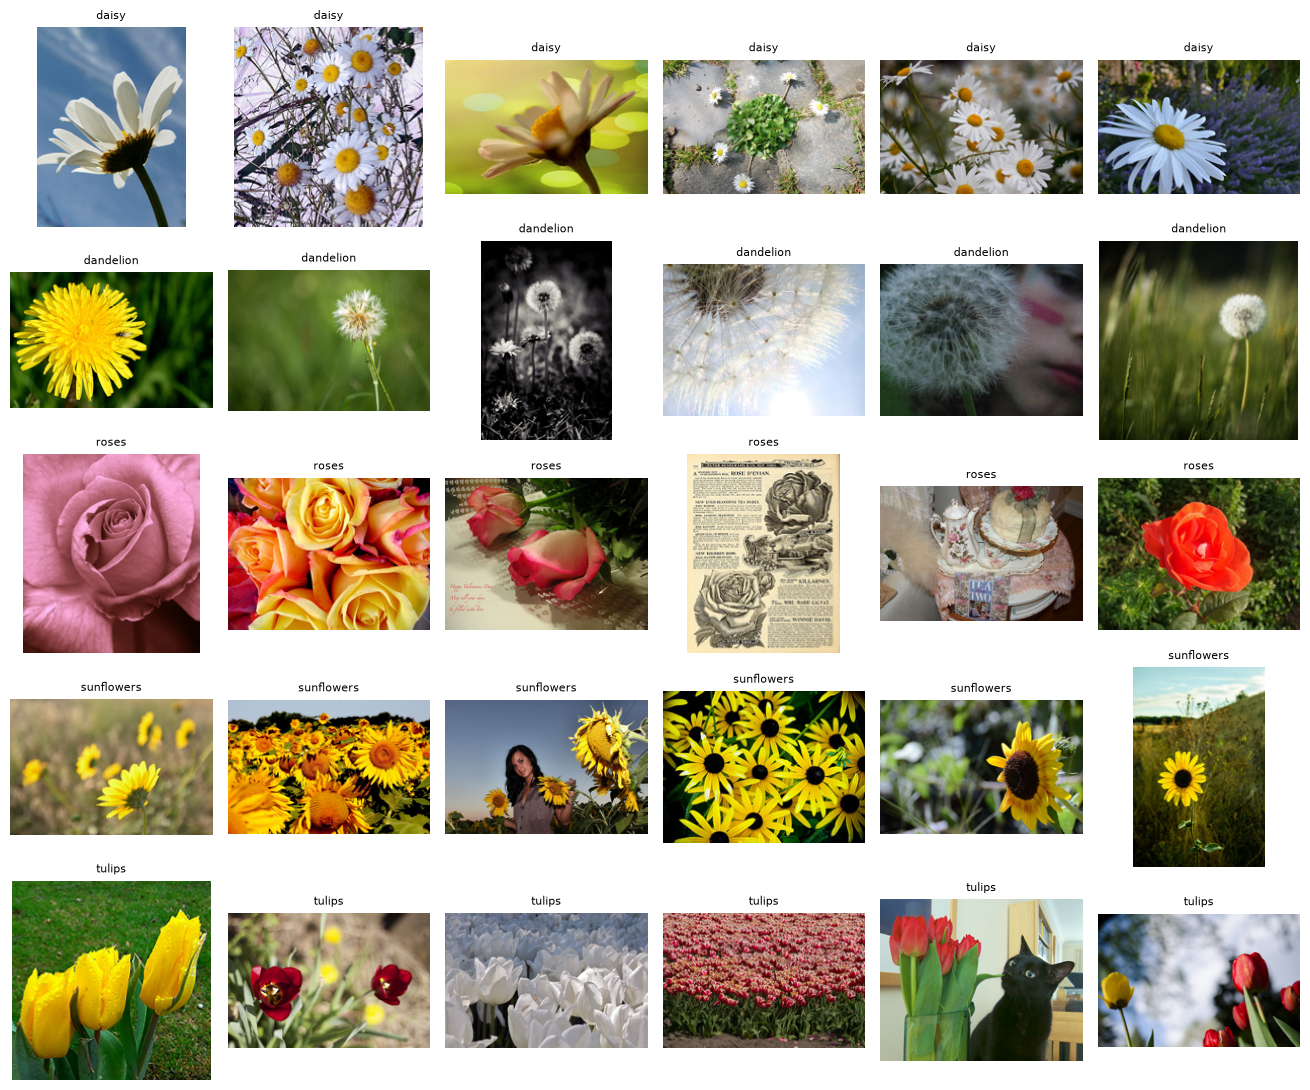

In [ ]:
# cate 6 exemple aleatoare din fiecare clasa
examples = df.groupby("class").sample(6, random_state=42)
lab4_common.show_images(examples["path"].tolist(), examples["class"].tolist(), ncols=6)

## 3. Incarcarea in memorie si redimensionarea

Pozele au dimensiuni diferite. Pentru retea toate trebuie sa aiba aceeasi marime, asa ca:
1. taiem un patrat din centrul pozei
2. il micsoram la 64 x 64 pixeli

Toate imaginile se tin in memorie ca un singur tensor (antrenarea e mult mai rapida decat citind pozele de pe disc la fiecare epoca).
Prima rulare dureaza putin; dupa aceea se citesc din `results/lab4/cache/`.

In [ ]:
df, X, y = lab4_common.load_dataset(img_size=64)
print("X:", tuple(X.shape), X.dtype, "-> (nr. imagini, canale RGB, inaltime, latime)")
print("y:", tuple(y.shape), "etichete", y.unique().tolist(), "=", lab4_common.CLASSES)
print(f"memorie: {X.numel() / 1024**2:.0f} MB")

X: (3670, 3, 64, 64) torch.uint8 -> (nr. imagini, canale RGB, inaltime, latime)
y: (3670,) etichete [0, 1, 2, 3, 4] = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
memorie: 43 MB


## 4. Cele 5 fold-uri comune

Impartim imaginile o singura data in 5 fold-uri (StratifiedKFold, `random_state=42`).
"Stratified" = in fiecare fold proportia claselor este aceeasi ca in tot setul.
Impartirea se salveaza in `results/lab4/folds.csv`, ca toate experimentele din echipa sa fie evaluate pe exact aceleasi imagini.

La fiecare experiment: antrenam pe 4 fold-uri si validam pe al 5-lea, de 5 ori, apoi facem media.

In [ ]:
fold = lab4_common.get_folds(df)
pd.crosstab(df["class"], fold, margins=True, margins_name="total").rename_axis(columns="fold")

fold,0,1,2,3,4,total
class,,,,,,
daisy,127,127,127,126,126,633
dandelion,180,179,179,180,180,898
roses,128,129,128,128,128,641
sunflowers,140,139,140,140,140,699
tulips,159,160,160,160,160,799
total,734,734,734,734,734,3670


## 5. Augmentarea

Augmentarea creeaza variante usor modificate ale pozelor de antrenare, ca reteaua sa nu "invete pe de rost" pozele.
Se aplica **doar la antrenare**, niciodata la validare. Fiecare poza poate fi:
- oglindita orizontal
- mutata cu cativa pixeli
- putin mai luminoasa/intunecata sau cu alt contrast

Mai jos: prima poza este originalul (64 x 64), celelalte sunt variante augmentate.

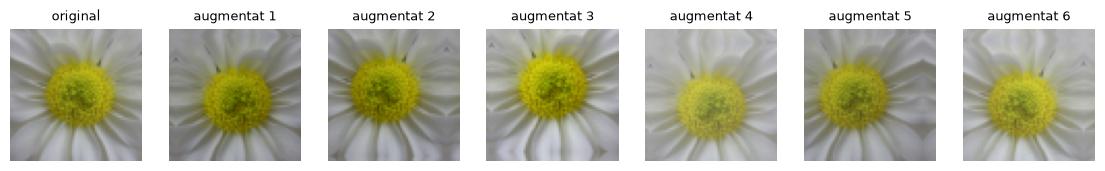

In [ ]:
torch.manual_seed(0)
img = lab4_common.to_float(X[:1]).repeat(7, 1, 1, 1)
aug = torch.cat([img[:1], lab4_common.augment(img[1:])])

fig, axes = plt.subplots(1, 7, figsize=(14, 2.3))
for i, ax in enumerate(axes):
    ax.imshow(((aug[i].permute(1, 2, 0) + 1) / 2).numpy())
    ax.set_title("original" if i == 0 else f"augmentat {i}", fontsize=9)
    ax.axis("off")
plt.show()

## 6. Reteaua de baza

Toate retelele se construiesc din acelasi dictionar de configurare (`lab4_common.DEFAULT_CONFIG`).
Fiecare experiment schimba doar parametrul pe care il testeaza, restul ramane ca in configurarea de baza.

Tabelul arata, pentru fiecare strat, forma tensorului la iesire si numarul de parametri.

In [ ]:
pd.Series(lab4_common.DEFAULT_CONFIG).to_frame("valoare")

,valoare
name,baseline
img_size,64
conv_layers,"[32, 64, 128]"
kernel_size,3
stride,1
pooling,max
recurrent,None
rnn_hidden,128
fc_layers,[128]
activation,relu


In [ ]:
lab4_common.model_summary(lab4_common.DEFAULT_CONFIG)

Layer (type:depth-idx)                   Output Shape              Param #
FlowerNet                                [1, 5]                    --
├─Sequential: 1-1                        [1, 128, 8, 8]            --
│    └─Conv2d: 2-1                       [1, 32, 64, 64]           896
│    └─ReLU: 2-2                         [1, 32, 64, 64]           --
│    └─MaxPool2d: 2-3                    [1, 32, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 64, 32, 32]           18,496
│    └─ReLU: 2-5                         [1, 64, 32, 32]           --
│    └─MaxPool2d: 2-6                    [1, 64, 16, 16]           --
│    └─Conv2d: 2-7                       [1, 128, 16, 16]          73,856
│    └─ReLU: 2-8                         [1, 128, 16, 16]          --
│    └─MaxPool2d: 2-9                    [1, 128, 8, 8]            --
├─Sequential: 1-2                        [1, 5]                    --
│    └─Linear: 2-10                      [1, 128]                  1,048,704

## 7. Test scurt de antrenare

Antrenam reteaua de baza doar 2 epoci, pe fold-ul 0, ca sa vedem ca totul functioneaza si cat dureaza o epoca.
Acest test **nu** salveaza nimic in rezultate.

In fiecare linie: `loss train/validare` si `F1 train/validare`. Dupa 2 epoci F1 trebuie sa fie deja peste 0.2 (cat ar da ghicitul la intamplare).

In [ ]:
cfg = lab4_common.make_config(name="test", epochs=2)
train_idx = np.where(fold != 0)[0]
val_idx = np.where(fold == 0)[0]

model, history, seconds = lab4_common.train_fold(cfg, X, y, train_idx, val_idx, device)
print(f"\n{seconds / len(history):.1f} secunde pe epoca pe {device}")
history.round(3)

  fold 0 epoca  1: loss 1.329/1.188  F1 0.420/0.495  (14s)
  fold 0 epoca  2: loss 1.108/1.037  F1 0.527/0.539  (26s)

12.8 secunde pe epoca pe cpu


,fold,epoch,train_loss,val_loss,train_f1,val_f1,seconds
0,0,1,1.329,1.188,0.420,0.495,13.914
1,0,2,1.108,1.037,0.527,0.539,25.633


## Concluzie

Daca toate celulele au rulat fara erori, baza comuna este gata:
- imaginile sunt incarcate (64 x 64), fold-urile comune sunt salvate in `results/lab4/folds.csv`
- reteaua se construieste si se antreneaza

Un experiment complet (5 fold-uri, pana la 30 de epoci) se ruleaza cu:

```python
cfg = lab4_common.make_config(name="numele_experimentului", ...modificari...)
lab4_common.run_experiment(cfg)
```

Fiecare experiment se salveaza in folderul lui, `results/lab4/runs/<nume_experiment>/`.
`lab4_common.load_log()` aduna toate experimentele terminate (si pe ale colegelor) intr-un singur tabel,
iar graficele se fac cu `plot_history`, `plot_confusion` si `plot_compare`.